In [1]:
# Data manipulation
import pandas as pd
import numpy as np
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
data = {
'TV_Advertising': [230, 44, 17, 151, 180, 8, 57, 120, 8, 200],
'Radio_Advertising': [37, 39, 45, 41, 10, 48, 32, 19, 2, 30],
'Social_Media': [69, 45, 69, 58, 12, 35, 23, 11, 1, 65],
'Sales': [22.1, 10.4, 9.3, 18.5, 12.9, 7.2, 11.8, 13.2, 4.8, 19.6]
}
df = pd.DataFrame(data)
df.head()

,TV_Advertising,Radio_Advertising,Social_Media,Sales
0,230,37,69,22.1
1,44,39,45,10.4
2,17,45,69,9.3
3,151,41,58,18.5
4,180,10,12,12.9


In [3]:
df['Response'] = np.where(df['Sales'] >= 12, 1, 0)
df[['Sales', 'Response']]

,Sales,Response
0,22.1,1
1,10.4,0
2,9.3,0
3,18.5,1
4,12.9,1
5,7.2,0
6,11.8,0
7,13.2,1
8,4.8,0
9,19.6,1


Response
1    5
0    5
Name: count, dtype: int64


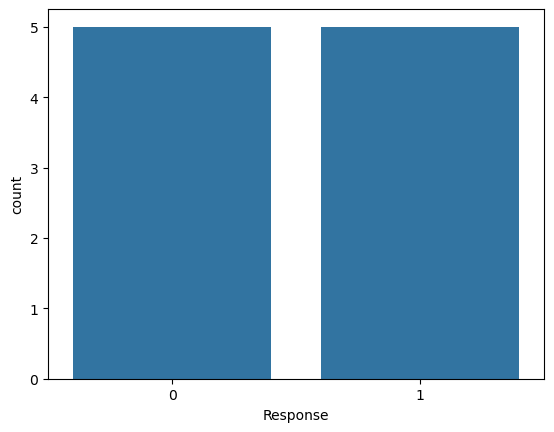

In [4]:
print(df['Response'].value_counts())
sns.countplot(x='Response', data=df)
plt.show()

In [5]:
X = df[['TV_Advertising', 'Radio_Advertising', 'Social_Media']]
y = df['Response']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42
)

In [7]:
log_model = LogisticRegression()
log_model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [8]:
print("Intercept:", log_model.intercept_)
print("Coefficients:", log_model.coef_)

Intercept: [-14.16696849]
Coefficients: [[ 0.17541653 -0.03357608 -0.02851116]]


In [9]:
odds_ratios = np.exp(log_model.coef_)
print("Odds Ratios:", odds_ratios)

Odds Ratios: [[1.19174251 0.96698134 0.97189145]]


In [10]:
y_pred = log_model.predict(X_test)

In [11]:
y_prob = log_model.predict_proba(X_test)
print(y_prob)
Probability for class 1:
print(y_prob[:,1])

SyntaxError: invalid syntax (2106089993.py, line 3)

In [12]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[3]]


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/sklearn/metrics/_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


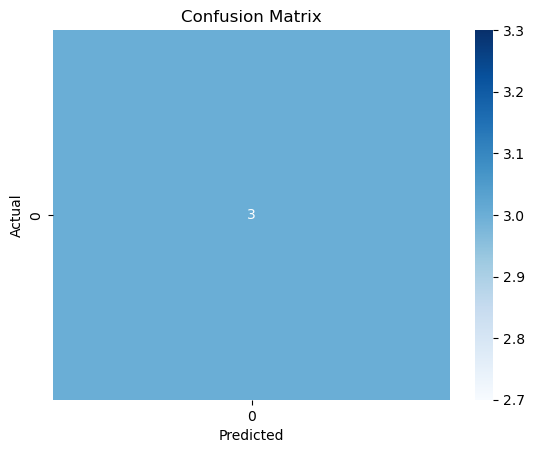

In [13]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



In [15]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 1.0


/opt/conda/envs/anaconda-2025.12-py312/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


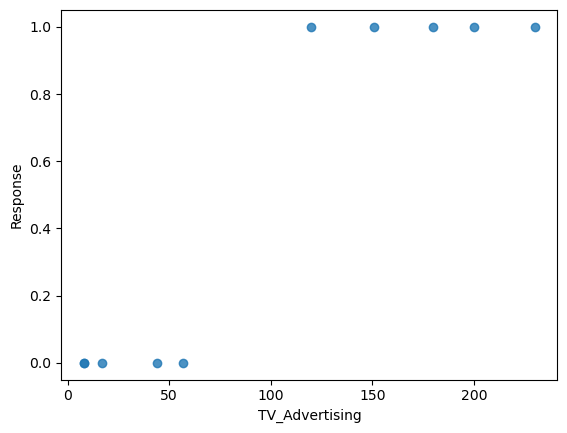

In [16]:
X_simple = df[['TV_Advertising']]
y_simple = df['Response']
model_simple = LogisticRegression()
model_simple.fit(X_simple, y_simple)
sns.regplot(x='TV_Advertising', y='Response', data=df, logistic=True)
plt.show()